# Exploratory data analysis: SMART-Z (2017–2018)

Report Section IV-D. Everything below uses the **training split of seed 0 only** (no validation/test data informs a design choice). All numbers are computed from the real feature store built by `scripts/run_pipeline.py --stage features`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
from tcse.utils import load_config
from tcse.eda import EDA
pd.set_option('display.width', 200)
cfg = load_config('../configs/default.yaml')
eda = EDA(cfg, 'smartz')
fig = lambda n: display(Image(filename=f'../results/figures/eda_smartz_{n}.png'))
print('attributes present in training data:', eda.attrs)

attributes present in training data: [5, 9, 193, 194, 197, 198, 199]


## 1. Summary statistics and class ratio per horizon

In [2]:
display(eda.summary_stats())
display(eda.class_ratio())

,attribute,name,missing_pct,mean,std,median,p99,max,nonzero_pct
0,5,Reallocated sectors,0.000,2.158000,54.455002,0.0,0.000000,2071.0,0.402
1,9,Power-on hours,0.000,15178.548828,4518.243164,15551.0,25583.660156,27105.0,100.000
2,193,Load/unload cycles,0.000,5.718000,9.916000,4.0,24.000000,1148.0,99.863
3,194,Temperature,0.001,30.528999,3.412000,31.0,39.000000,65.0,99.999
4,197,Pending sectors,0.000,0.830000,22.083000,0.0,3.000000,2155.0,2.089
5,198,Offline uncorrectable,0.000,0.306000,17.172001,0.0,0.000000,2788.0,0.310
6,199,UDMA CRC errors,0.000,2762.491943,17784.357422,0.0,88082.000000,493244.0,9.911


,H,train_rows,positives,positive_pct,healthy_per_failure,failed_drives_with_positives
0,1,2480144,89,0.0036,27865.8,89
1,7,2468351,490,0.0199,5036.5,105
2,14,2454078,993,0.0405,2470.4,112
3,30,2383154,1883,0.0790,1264.6,118


## 2. Missing-data patterns (raw values, before forward fill)

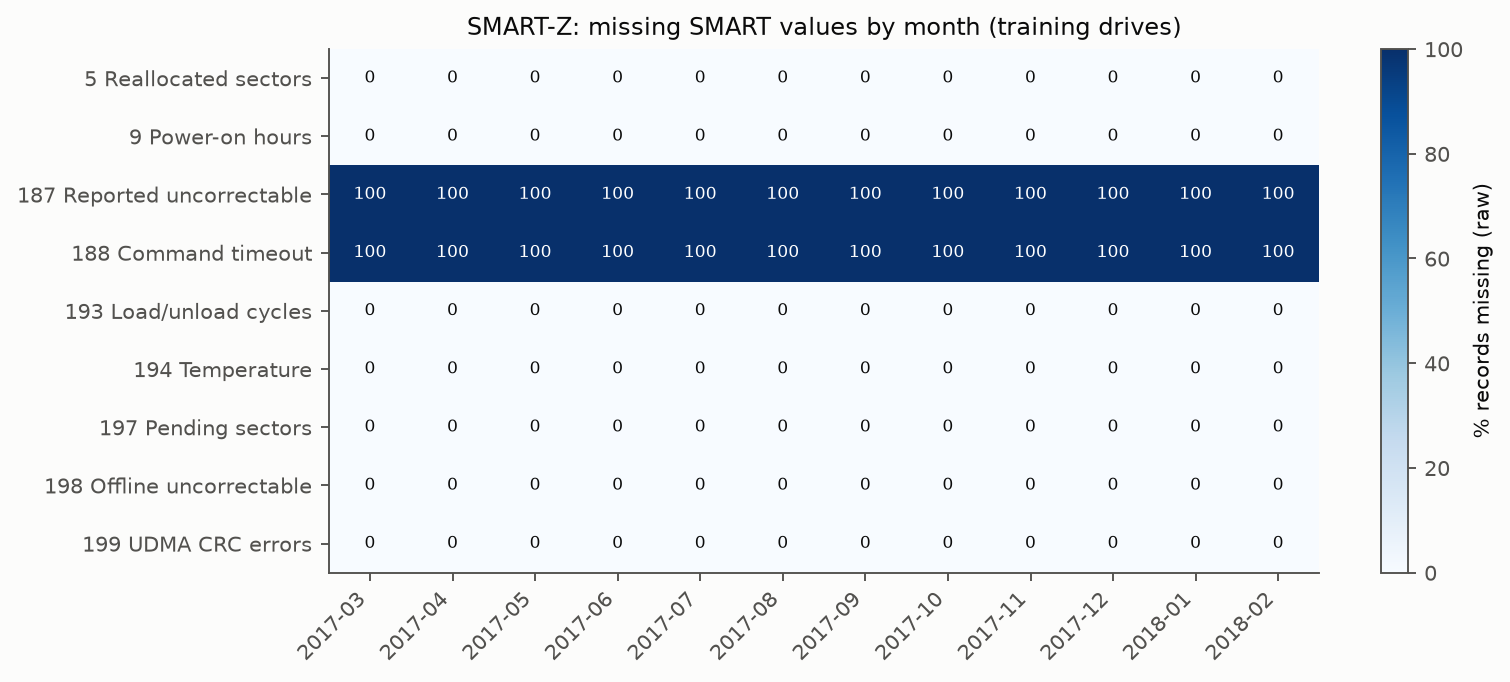

In [3]:
miss = eda.missingness(); fig('missingness')

## 3. Failed vs. healthy drives: box plots and Kolmogorov–Smirnov tests

,attribute,name,n_failed,n_healthy,median_failed,median_healthy,mean_failed,mean_healthy,KS_D,KS_p
4,197,Pending sectors,118,15921,1.0,0.0,103.686440,0.848439,0.564395,1.061951e-35
2,193,Load/unload cycles,118,15921,6.0,5.0,16.533897,5.767602,0.167966,2.356117e-03
5,198,Offline uncorrectable,118,15921,0.0,0.0,44.245762,0.373469,0.140802,1.738692e-02
3,194,Temperature,118,15921,32.0,31.0,31.593220,30.643301,0.140136,1.817805e-02
0,5,Reallocated sectors,118,15921,0.0,0.0,99.186440,2.086992,0.122910,5.343234e-02
1,9,Power-on hours,118,15921,15032.5,15656.0,14771.771484,15271.037109,0.084991,3.469613e-01
6,199,UDMA CRC errors,118,15921,0.0,0.0,2006.872925,2516.770996,0.020307,1.000000e+00


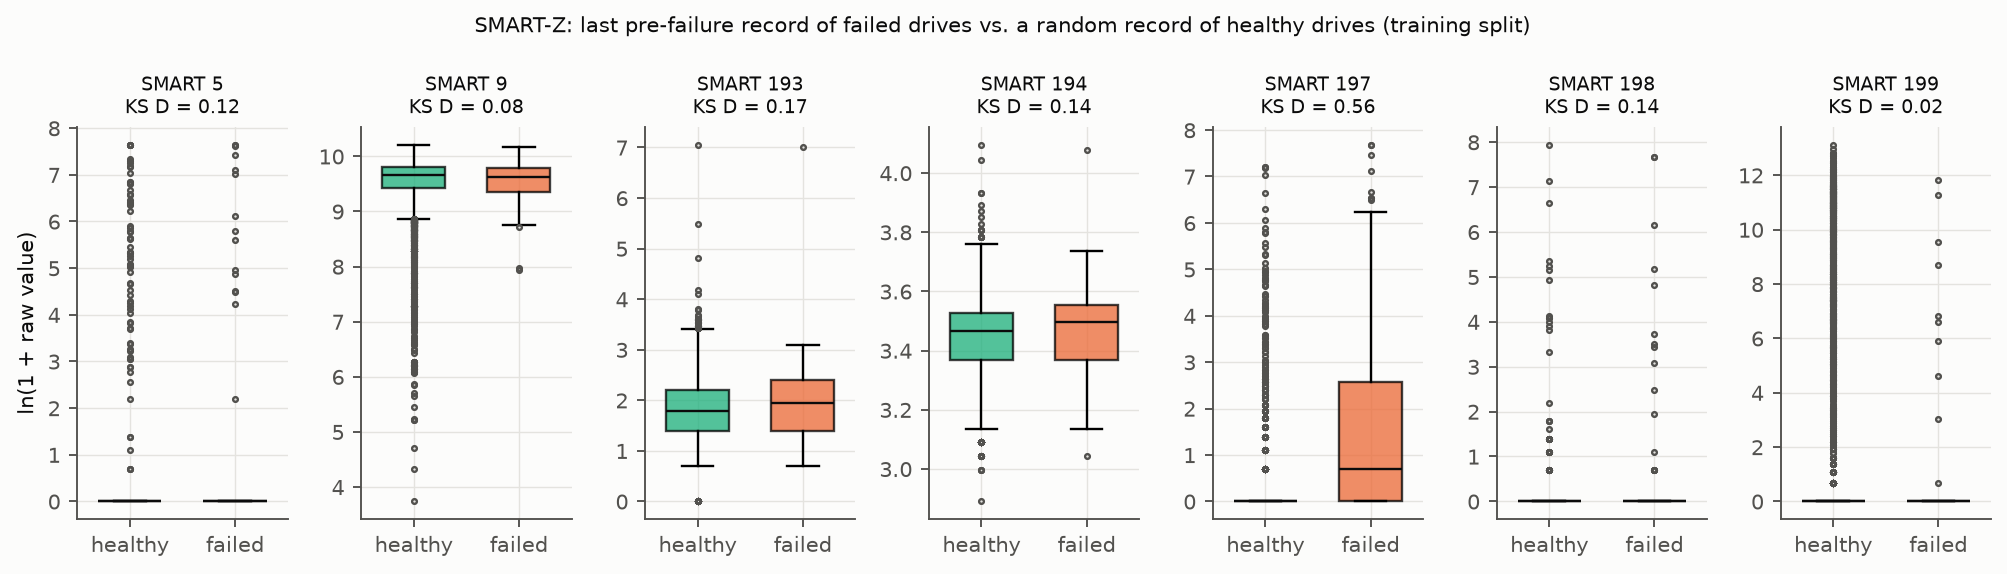

In [4]:
ks = eda.failed_vs_healthy(); display(ks); fig('boxplots_ks')

## 4. Attribute correlations

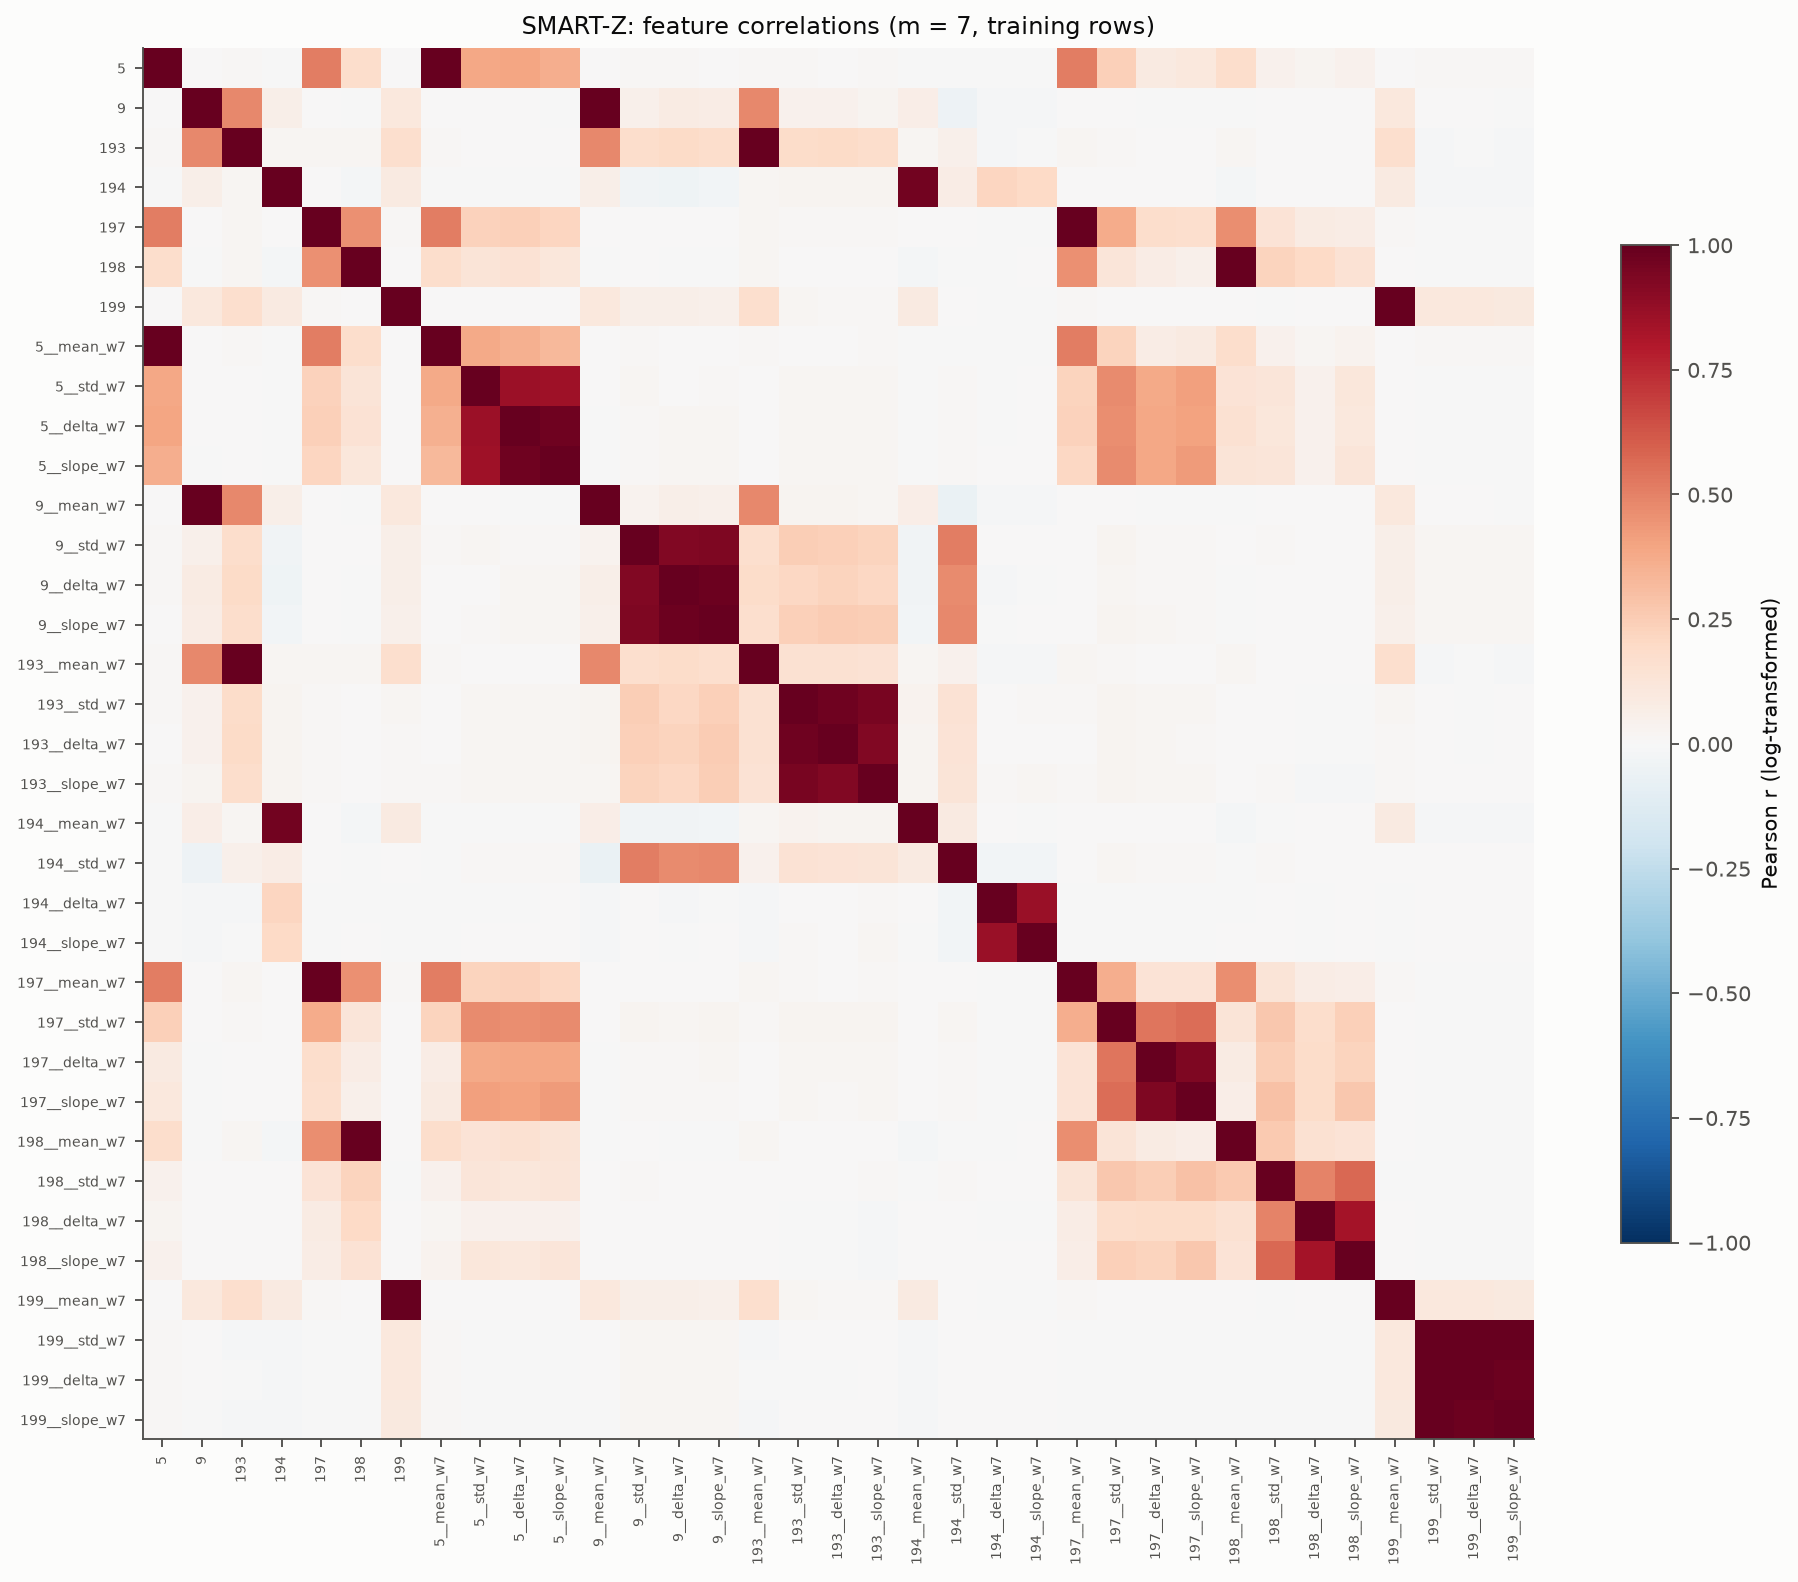

pairs with |r| > 0.95 (one of each is dropped by feature selection):
('smart_5_raw', 'smart_5_raw__mean_w7', np.float64(0.997))
('smart_9_raw', 'smart_9_raw__mean_w7', np.float64(0.997))
('smart_193_raw', 'smart_193_raw__mean_w7', np.float64(0.999))
('smart_194_raw', 'smart_194_raw__mean_w7', np.float64(0.961))
('smart_197_raw', 'smart_197_raw__mean_w7', np.float64(0.998))
('smart_198_raw', 'smart_198_raw__mean_w7', np.float64(0.995))
('smart_199_raw', 'smart_199_raw__mean_w7', np.float64(1.0))
('smart_5_raw__delta_w7', 'smart_5_raw__slope_w7', np.float64(0.974))
('smart_9_raw__delta_w7', 'smart_9_raw__slope_w7', np.float64(0.977))
('smart_193_raw__std_w7', 'smart_193_raw__delta_w7', np.float64(0.976))
('smart_199_raw__std_w7', 'smart_199_raw__delta_w7', np.float64(0.994))
('smart_199_raw__std_w7', 'smart_199_raw__slope_w7', np.float64(0.995))
('smart_199_raw__delta_w7', 'smart_199_raw__slope_w7', np.float64(0.979))


In [5]:
R, high = eda.correlation(); fig('correlation')
print('pairs with |r| > 0.95 (one of each is dropped by feature selection):')
for h in high: print(h)

## 5. Average 30-day pre-failure trajectories

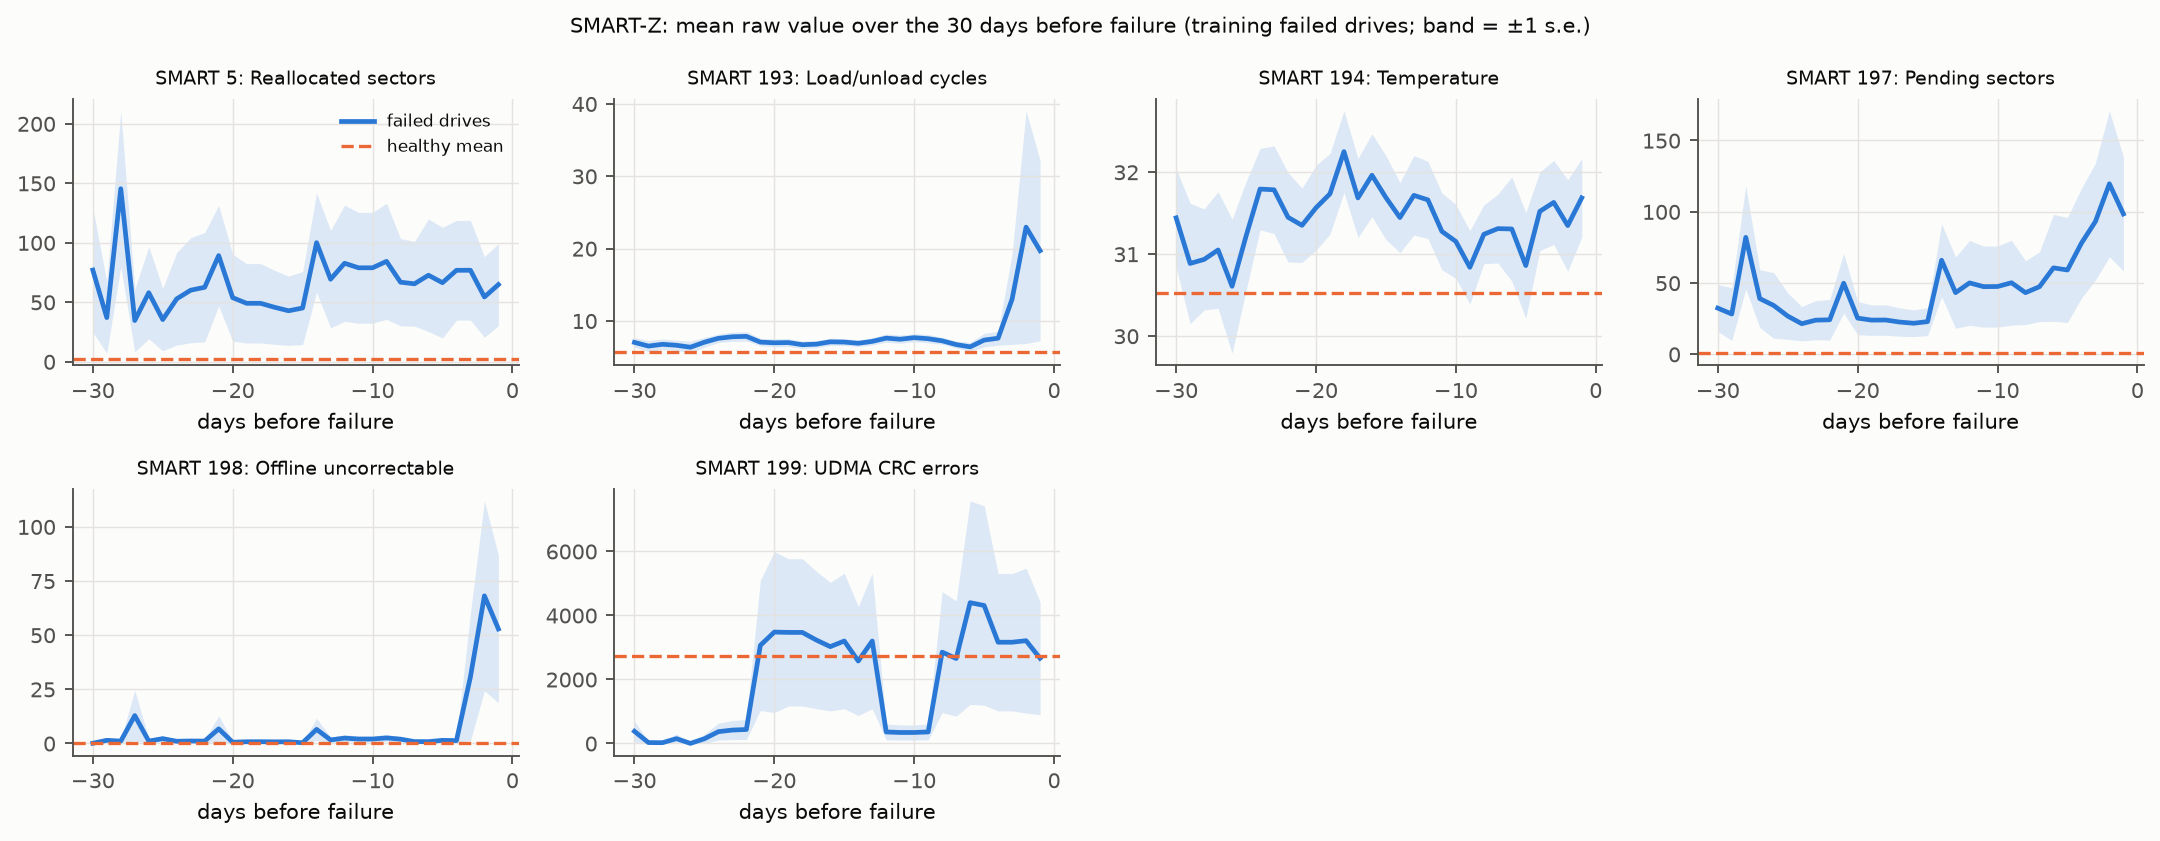

In [6]:
traj = eda.prefailure_trajectories(); fig('prefailure_trajectories')

## 6. Two-dimensional PCA projection

explained variance ratio: [0.214  0.1112]


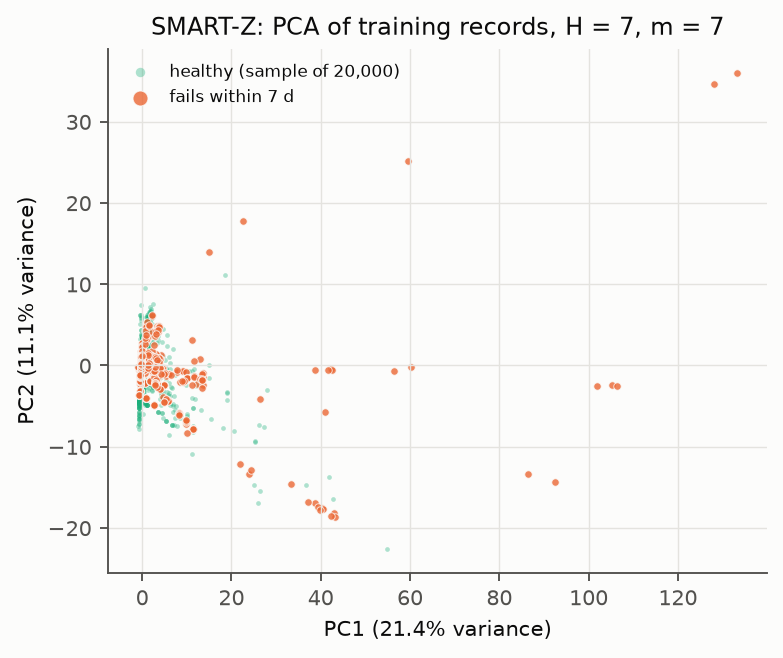

In [7]:
ev = eda.pca(); print('explained variance ratio:', ev.round(4)); fig('pca')

## 7. Choice of the trend window m

KS separation (healthy vs. fails-within-7-days rows) of the delta / slope / std trend features for each candidate window, plus the window chosen on the validation set by `tcse.experiments.select_window` (TCSE validation cost).

In [8]:
piv, summ = eda.window_separation(); display(summ); display(piv)
import json, pathlib
for f in pathlib.Path('../results/metrics/window_selection').glob('smartz*/chosen.json'): print(f.parent.name, json.loads(f.read_text()))

,mean,median,max
m,,,
3,0.0538,0.0224,0.1641
7,0.0851,0.0467,0.2605
14,0.1005,0.0650,0.3529


m                   3      7      14
attribute stat                      
5         delta  0.020  0.036  0.042
          slope  0.020  0.036  0.042
          std    0.020  0.036  0.042
9         delta  0.111  0.201  0.138
          slope  0.111  0.175  0.111
          std    0.108  0.198  0.181
193       delta  0.020  0.012  0.031
          slope  0.020  0.019  0.032
          std    0.023  0.018  0.041
194       delta  0.051  0.062  0.050
          slope  0.055  0.047  0.102
          std    0.070  0.074  0.083
197       delta  0.132  0.231  0.310
          slope  0.132  0.233  0.318
          std    0.164  0.261  0.353
198       delta  0.022  0.047  0.065
          slope  0.022  0.047  0.065
          std    0.022  0.049  0.067
199       delta  0.002  0.002  0.012
          slope  0.002  0.002  0.012
          std    0.002  0.002  0.012

smartz {'window': 14, 'val_average_precision': {'3': 0.00394642704238401, '7': 0.0034131370849055254, '14': 0.004018368778050775}, 'val_cost': {'3': 1010.0, '7': 1010.0, '14': 1010.0}, 'criterion': 'max TCSE validation average precision (ties: validation cost at r=10), H=7, seed=0'}
